# Round 2 Backtest Log Analysis

This notebook reads Prosperity backtest JSON outputs, parses the embedded `activitiesLog` and `graphLog`, and compares trials side by side.

It is designed to help answer questions like:
- when does a trial make or lose money
- how smooth is the PnL path
- what is happening in the ASH order book when the trial is active
- which trials look stable versus fragile

In [1]:
from io import StringIO
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

# Notebook parameters:
# - set TARGET_TRIAL to a trial folder name like "trial4"
# - set OUTPUT_STEM to control the exported file names
TARGET_TRIAL = "trial4"
OUTPUT_STEM = f"{TARGET_TRIAL}_backtest_log_report"
OUTPUT_DIR = None

def find_repo_root(start=None):
    start_path = Path(start or Path.cwd()).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / "R1" / "trial1").exists():
            return candidate
    return start_path

ROOT = find_repo_root()
REPORT_DIR = Path(OUTPUT_DIR) if OUTPUT_DIR else (ROOT / "R1" / "erick" / "backtest_reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

trial_json_paths = sorted(ROOT.glob(f"R1/{TARGET_TRIAL}/*.json"))
if not trial_json_paths:
    trial_json_paths = sorted(ROOT.glob("R1/trial*/[0-9]*.json"))

trial_json_paths[:5], len(trial_json_paths), REPORT_DIR

([PosixPath('/Users/ericlu/Works/imcp4/imcprosp4/R1/trial4/123161.json')],
 1,
 PosixPath('/Users/ericlu/Works/imcp4/imcprosp4/R1/erick/backtest_reports'))

In [2]:
def load_backtest_json(path):
    raw = json.loads(path.read_text())
    activities = pd.read_csv(StringIO(raw["activitiesLog"]), sep=";")
    graph = pd.read_csv(StringIO(raw["graphLog"]), sep=";")
    activities = activities.replace("", np.nan)
    graph = graph.replace("", np.nan)

    numeric_activity_cols = [
        "day",
        "timestamp",
        "bid_price_1",
        "bid_volume_1",
        "bid_price_2",
        "bid_volume_2",
        "bid_price_3",
        "bid_volume_3",
        "ask_price_1",
        "ask_volume_1",
        "ask_price_2",
        "ask_volume_2",
        "ask_price_3",
        "ask_volume_3",
        "mid_price",
        "profit_and_loss",
    ]
    for column in numeric_activity_cols:
        if column in activities.columns:
            activities[column] = pd.to_numeric(activities[column], errors="coerce")
    for column in ["timestamp", "value"]:
        if column in graph.columns:
            graph[column] = pd.to_numeric(graph[column], errors="coerce")

    trial_name = path.parent.name
    activities["trial"] = trial_name
    graph["trial"] = trial_name
    return raw, activities, graph


def ash_slice(activities):
    return activities[activities["product"] == "ASH_COATED_OSMIUM"].copy()


def max_drawdown(series):
    running_max = series.cummax()
    drawdown = running_max - series
    return float(drawdown.max())


def summarize_trial(path):
    raw, activities, graph = load_backtest_json(path)
    ash = ash_slice(activities).sort_values(["day", "timestamp"]).copy()
    ash = ash[ash["mid_price"].notna()].copy()
    ash = ash[(ash["mid_price"] > 0) & (ash["bid_price_1"] > 0) & (ash["ask_price_1"] > 0)].copy()
    ash["spread"] = ash["ask_price_1"] - ash["bid_price_1"]
    ash["top_depth"] = ash[["bid_volume_1", "ask_volume_1"]].min(axis=1)

    graph = graph.dropna(subset=["timestamp", "value"]).sort_values("timestamp")
    pnl = graph["value"]
    if len(pnl) == 0:
        final_pnl = np.nan
        peak_pnl = np.nan
        valley_pnl = np.nan
        pnl_drawdown = np.nan
    else:
        final_pnl = float(pnl.iloc[-1])
        peak_pnl = float(pnl.max())
        valley_pnl = float(pnl.min())
        pnl_drawdown = max_drawdown(pnl)

    breakeven_ts = np.nan
    if len(graph) and (graph["value"] > 0).any():
        breakeven_ts = float(graph.loc[graph["value"] > 0, "timestamp"].iloc[0])

    return {
        "trial": path.parent.name,
        "path": str(path),
        "round": raw.get("round"),
        "status": raw.get("status"),
        "final_profit": float(raw.get("profit", np.nan)),
        "graph_final": final_pnl,
        "graph_peak": peak_pnl,
        "graph_valley": valley_pnl,
        "graph_drawdown": pnl_drawdown,
        "breakeven_timestamp": breakeven_ts,
        "ash_rows": int(len(ash)),
        "ash_days": int(ash["day"].nunique()) if len(ash) else 0,
        "ash_mid_first": float(ash["mid_price"].iloc[0]) if len(ash) else np.nan,
        "ash_mid_last": float(ash["mid_price"].iloc[-1]) if len(ash) else np.nan,
        "ash_spread_mean": float(ash["spread"].mean()) if len(ash) else np.nan,
        "ash_spread_median": float(ash["spread"].median()) if len(ash) else np.nan,
        "ash_top_depth_mean": float(ash["top_depth"].mean()) if len(ash) else np.nan,
    }

trial_data = []
for path in trial_json_paths:
    raw, activities, graph = load_backtest_json(path)
    trial_data.append({
        "meta": summarize_trial(path),
        "activities": activities,
        "graph": graph,
    })

summary_df = pd.DataFrame([item["meta"] for item in trial_data]).sort_values("final_profit", ascending=False)
summary_df

,trial,path,round,status,final_profit,graph_final,graph_peak,graph_valley,graph_drawdown,breakeven_timestamp,ash_rows,ash_days,ash_mid_first,ash_mid_last,ash_spread_mean,ash_spread_median,ash_top_depth_mean
0,trial4,/Users/ericlu/Works/imcp4/imcprosp4/R1/trial4/...,1,FINISHED,4927.9375,4924.125,4924.125,0.0,47.375,1200.0,914,1,10001.5,10003.0,16.253829,16.0,12.389497


In [ ]:
summary_df

In [3]:
report_csv_path = REPORT_DIR / f"{OUTPUT_STEM}.csv"
report_md_path = REPORT_DIR / f"{OUTPUT_STEM}.md"
summary_df.to_csv(report_csv_path, index=False)

selected_meta = summary_df.iloc[0].to_dict()
report_lines = [
    f"# Backtest Log Report: {selected_meta['trial']}",
    "",
    f"- Source: `{selected_meta['path']}`",
    f"- Round: {selected_meta['round']}",
    f"- Status: {selected_meta['status']}",
    f"- Final profit: {selected_meta['final_profit']:.2f}",
    f"- Graph final: {selected_meta['graph_final']:.2f}",
    f"- Graph drawdown: {selected_meta['graph_drawdown']:.2f}",
    f"- Breakeven timestamp: {selected_meta['breakeven_timestamp']}",
    "",
    "## Summary Table",
    "",
    summary_df.to_markdown(index=False),
]
report_md_path.write_text("\n".join(report_lines))

report_csv_path, report_md_path

(PosixPath('/Users/ericlu/Works/imcp4/imcprosp4/R1/erick/backtest_reports/trial4_backtest_log_report.csv'),
 PosixPath('/Users/ericlu/Works/imcp4/imcprosp4/R1/erick/backtest_reports/trial4_backtest_log_report.md'))

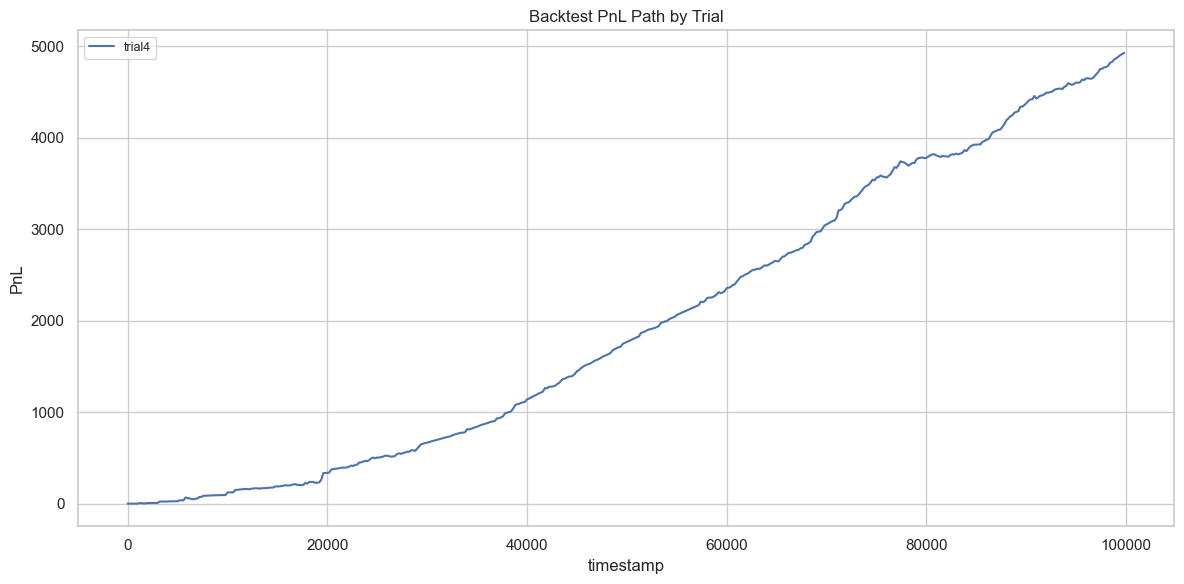

PosixPath('/Users/ericlu/Works/imcp4/imcprosp4/R1/erick/backtest_reports/trial4_backtest_log_report_comparison.png')

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))
for item in trial_data:
    graph = item["graph"].dropna(subset=["timestamp", "value"]).sort_values("timestamp")
    ax.plot(graph["timestamp"], graph["value"], label=item["meta"]["trial"])

ax.set_title("Backtest PnL Path by Trial")
ax.set_xlabel("timestamp")
ax.set_ylabel("PnL")
ax.legend(ncol=2, fontsize=9)
plt.tight_layout()
comparison_plot_path = REPORT_DIR / f"{OUTPUT_STEM}_comparison.png"
fig.savefig(comparison_plot_path, dpi=150, bbox_inches="tight")
plt.show()
comparison_plot_path

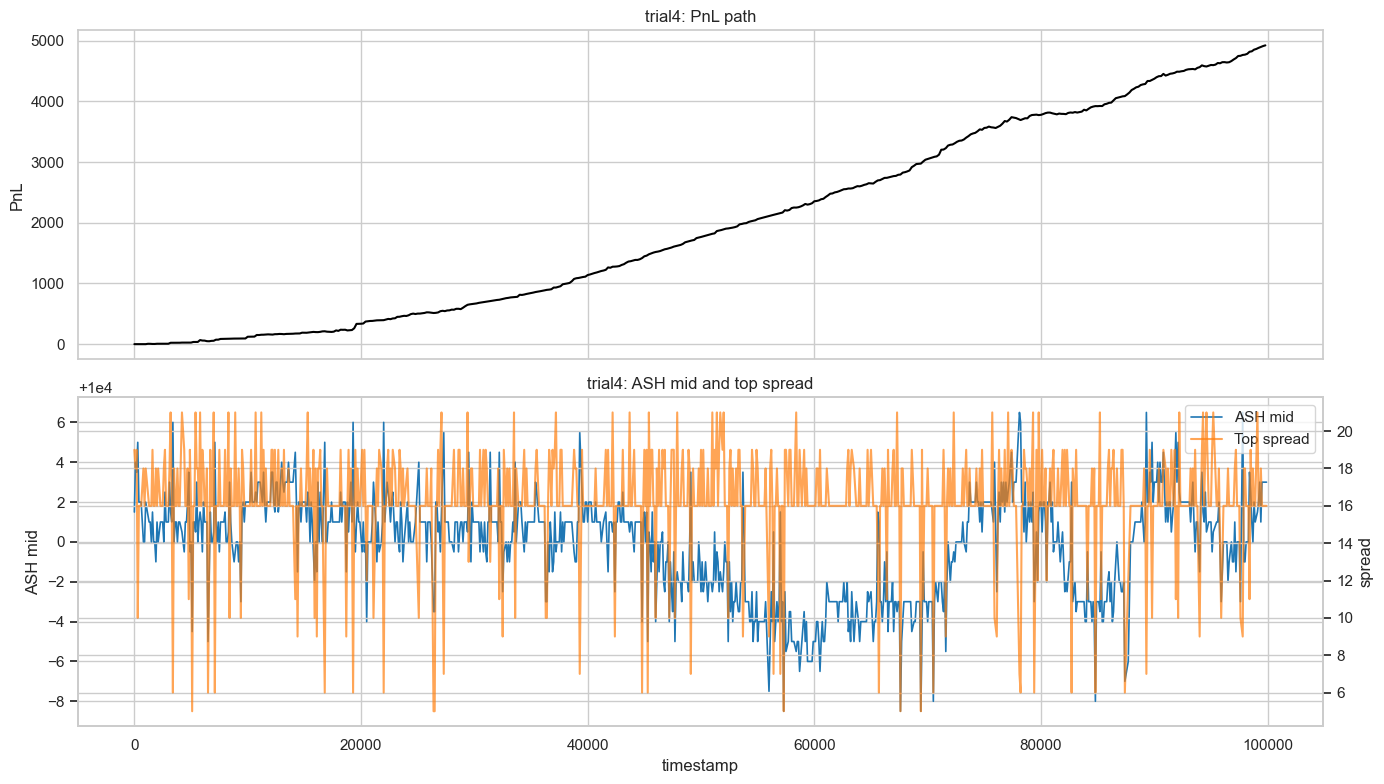

PosixPath('/Users/ericlu/Works/imcp4/imcprosp4/R1/erick/backtest_reports/trial4_backtest_log_report_trial4.png')

In [5]:
def plot_trial(trial_name):
    match = next((item for item in trial_data if item["meta"]["trial"] == trial_name), None)
    if match is None:
        raise ValueError(f"Unknown trial: {trial_name}")

    activities = match["activities"].copy()
    graph = match["graph"].dropna(subset=["timestamp", "value"]).sort_values("timestamp")
    ash = ash_slice(activities).sort_values(["day", "timestamp"]).copy()
    ash = ash[ash["mid_price"].notna()].copy()
    ash = ash[(ash["mid_price"] > 0) & (ash["bid_price_1"] > 0) & (ash["ask_price_1"] > 0)].copy()
    ash["spread"] = ash["ask_price_1"] - ash["bid_price_1"]

    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

    axes[0].plot(graph["timestamp"], graph["value"], color="black", linewidth=1.5)
    axes[0].set_title(f"{trial_name}: PnL path")
    axes[0].set_ylabel("PnL")

    mid_line = axes[1].plot(ash["timestamp"], ash["mid_price"], label="ASH mid", color="tab:blue", linewidth=1.2)
    spread_ax = axes[1].twinx()
    spread_line = spread_ax.plot(ash["timestamp"], ash["spread"], label="Top spread", color="tab:orange", alpha=0.7)
    axes[1].set_title(f"{trial_name}: ASH mid and top spread")
    axes[1].set_xlabel("timestamp")
    axes[1].set_ylabel("ASH mid")
    spread_ax.set_ylabel("spread")

    lines = mid_line + spread_line
    labels = [line.get_label() for line in lines]
    axes[1].legend(lines, labels, loc="upper right")

    plt.tight_layout()
    detail_plot_path = REPORT_DIR / f"{OUTPUT_STEM}_{trial_name}.png"
    fig.savefig(detail_plot_path, dpi=150, bbox_inches="tight")
    plt.show()
    return detail_plot_path

plot_trial(summary_df.iloc[0]["trial"])

## PEPPER-focused log comparison: trials 5, 19, 20, 21

This section parses raw `.log` backtest outputs directly and compares where each strategy performs or struggles:
- day-level PEPPER PnL
- intraday PnL contribution by time bucket
- drawdown severity and recovery profile
- volatility of incremental PnL

In [2]:
import re
from io import StringIO

TRIAL_LOGS = {
    "trial5": ROOT / "R1" / "erick" / "backtest_reports" / "trial5_pepper_compare.log",
    "trial19": ROOT / "R1" / "erick" / "backtest_reports" / "trial19_pepper_compare.log",
    "trial20": ROOT / "R1" / "erick" / "backtest_reports" / "trial20_pepper_compare.log",
    "trial21": ROOT / "R1" / "erick" / "backtest_reports" / "trial21_pepper_compare.log",
}

PEPPER = "INTARIAN_PEPPER_ROOT"


def parse_activities_from_log(log_path: Path) -> pd.DataFrame:
    lines = log_path.read_text().splitlines()
    start = lines.index("Activities log:") + 1

    header = None
    rows = []
    row_re = re.compile(r"^-?\d+;")

    for line in lines[start:]:
        s = line.strip()
        if not s:
            if header is not None:
                break
            continue
        if header is None:
            if s.startswith("day;timestamp;"):
                header = s
            continue
        if row_re.match(s):
            rows.append(s)
        else:
            break

    if header is None or not rows:
        raise ValueError(f"Could not parse activities table in {log_path}")

    df = pd.read_csv(StringIO("\n".join([header, *rows])), sep=";")
    df = df.replace("", np.nan)

    numeric_cols = [
        "day",
        "timestamp",
        "bid_price_1",
        "bid_volume_1",
        "bid_price_2",
        "bid_volume_2",
        "bid_price_3",
        "bid_volume_3",
        "ask_price_1",
        "ask_volume_1",
        "ask_price_2",
        "ask_volume_2",
        "ask_price_3",
        "ask_volume_3",
        "mid_price",
        "profit_and_loss",
    ]
    for col in numeric_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    return df


trial_frames = []
for trial, path in TRIAL_LOGS.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing log for {trial}: {path}")
    frame = parse_activities_from_log(path)
    frame["trial"] = trial
    trial_frames.append(frame)

all_activities_df = pd.concat(trial_frames, ignore_index=True)
pepper_df = all_activities_df[all_activities_df["product"] == PEPPER].copy()
pepper_df = pepper_df.sort_values(["trial", "day", "timestamp"]).reset_index(drop=True)

all_activities_df.shape, pepper_df.shape, pepper_df[["trial", "day"]].drop_duplicates().sort_values(["trial", "day"]).head(12)

((240000, 18),
 (120000, 18),
           trial  day
 0       trial19   -2
 10000   trial19   -1
 20000   trial19    0
 30000   trial20   -2
 40000   trial20   -1
 50000   trial20    0
 60000   trial21   -2
 70000   trial21   -1
 80000   trial21    0
 90000    trial5   -2
 100000   trial5   -1
 110000   trial5    0)

In [3]:
def _max_drawdown_from_path(pnl_series: pd.Series) -> float:
    if len(pnl_series) == 0:
        return np.nan
    run_max = pnl_series.cummax()
    return float((run_max - pnl_series).max())


pepper_paths = pepper_df.copy()
pepper_paths["pnl_step"] = pepper_paths.groupby(["trial", "day"])["profit_and_loss"].diff()
pepper_paths["pnl_step"] = pepper_paths["pnl_step"].fillna(pepper_paths["profit_and_loss"])

# Intraday bucket assignment robust to ties and repeated timestamps.
pepper_paths["bucket_frac"] = pepper_paths.groupby(["trial", "day"])["timestamp"].rank(method="first", pct=True)
pepper_paths["time_bucket"] = np.minimum((pepper_paths["bucket_frac"] * 10).astype(int), 9)

pepper_day_end = (
    pepper_paths.groupby(["trial", "day"], as_index=False)
    .tail(1)[["trial", "day", "profit_and_loss"]]
    .rename(columns={"profit_and_loss": "pepper_day_pnl"})
    .sort_values(["trial", "day"])
)

pepper_trial_summary = (
    pepper_day_end.groupby("trial", as_index=False)
    .agg(
        pepper_total_pnl=("pepper_day_pnl", "sum"),
        pepper_best_day=("pepper_day_pnl", "max"),
        pepper_worst_day=("pepper_day_pnl", "min"),
        pepper_day_std=("pepper_day_pnl", "std"),
    )
)

pepper_dd = (
    pepper_paths.groupby(["trial", "day"], as_index=False)
    .apply(lambda g: pd.Series({
        "pepper_day_max_dd": _max_drawdown_from_path(g["profit_and_loss"]),
        "pepper_step_std": float(g["pnl_step"].std()),
        "pepper_positive_step_ratio": float((g["pnl_step"] > 0).mean()),
    }), include_groups=False)
    .reset_index()
)

pepper_dd = pepper_dd.drop(columns=["level_2"], errors="ignore")

pepper_bucket_pnl = (
    pepper_paths.groupby(["trial", "time_bucket"], as_index=False)
    .agg(bucket_pnl=("pnl_step", "sum"))
)

pepper_summary_full = (
    pepper_trial_summary
    .merge(
        pepper_dd.groupby("trial", as_index=False).agg(
            avg_day_max_dd=("pepper_day_max_dd", "mean"),
            worst_day_max_dd=("pepper_day_max_dd", "max"),
            avg_step_std=("pepper_step_std", "mean"),
            avg_positive_step_ratio=("pepper_positive_step_ratio", "mean"),
        ),
        on="trial",
        how="left",
    )
    .sort_values("pepper_total_pnl", ascending=False)
)

display(pepper_day_end, pepper_summary_full.round(3))

,trial,day,pepper_day_pnl
9999,trial19,-2,31595.0
19999,trial19,-1,23300.0
29999,trial19,0,23776.0
39999,trial20,-2,27339.5
49999,trial20,-1,29989.0
59999,trial20,0,30800.0
69999,trial21,-2,29796.5
79999,trial21,-1,28982.0
89999,trial21,0,27831.0
99999,trial5,-2,33333.0


,trial,pepper_total_pnl,pepper_best_day,pepper_worst_day,pepper_day_std,avg_day_max_dd,worst_day_max_dd,avg_step_std,avg_positive_step_ratio
3,trial5,103129.0,34986.0,33333.0,907.828,563186.333,607534.0,24617.718,0.366
1,trial20,88128.5,30800.0,27339.5,1809.817,511312.667,542156.0,19136.682,0.381
2,trial21,86609.5,29796.5,27831.0,987.539,592059.333,640568.0,18954.226,0.366
0,trial19,78671.0,31595.0,23300.0,4657.796,676306.333,780331.0,19233.740,0.356


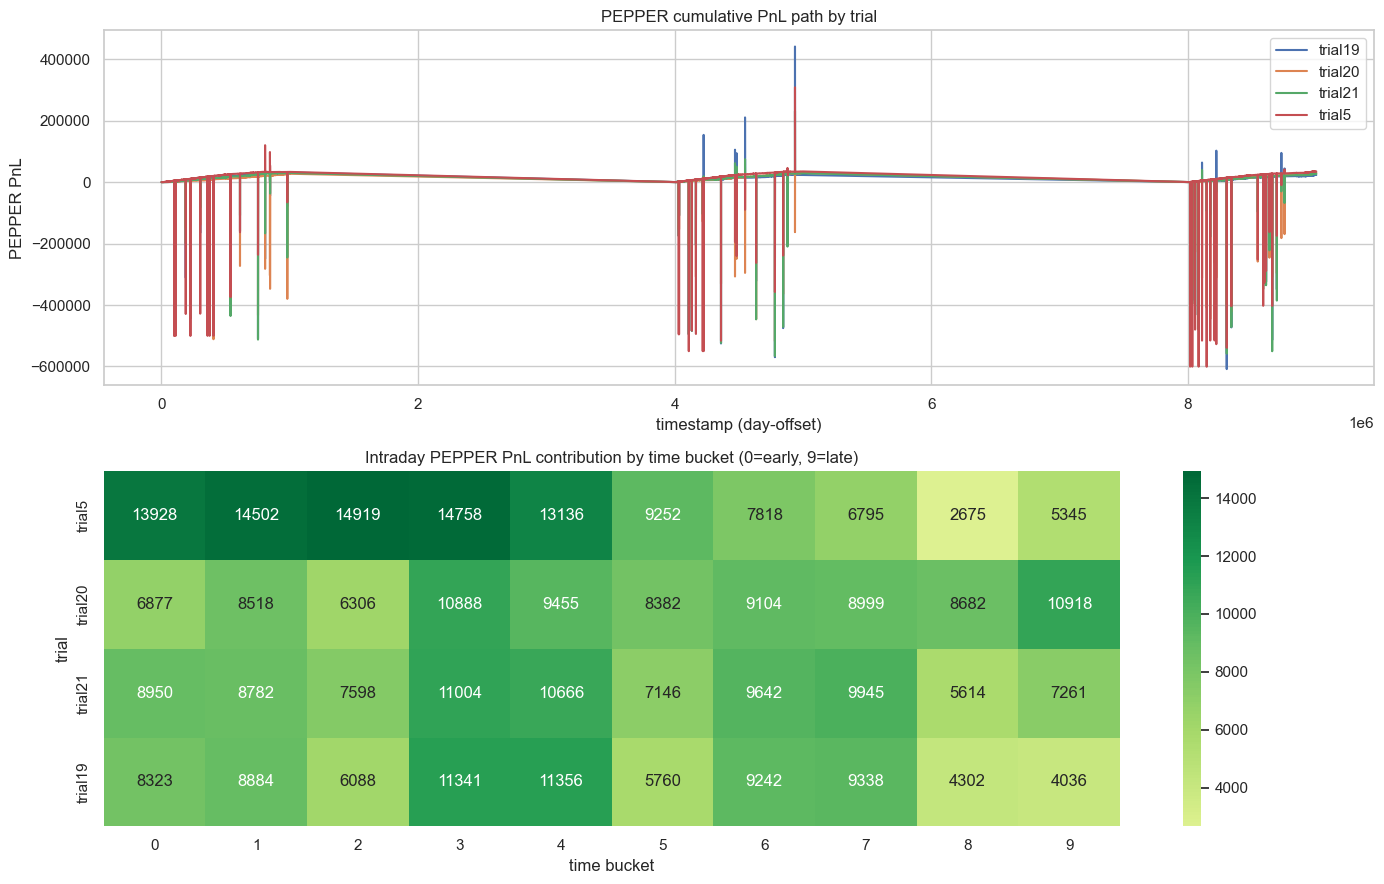

time_bucket,0,1,2,3,4,5,6,7,8,9
trial,,,,,,,,,,
trial5,13928.0,14502.5,14919.0,14758.5,13136.5,9251.5,7818.0,6795.0,2675.0,5345.0
trial20,6877.0,8518.5,6306.5,10888.0,9455.0,8381.5,9103.5,8999.0,8682.0,10917.5
trial21,8950.5,8782.5,7597.5,11004.5,10666.0,7145.5,9642.5,9945.0,5614.5,7261.0
trial19,8323.0,8883.5,6088.5,11341.0,11356.5,5759.5,9242.5,9337.5,4302.5,4036.5


In [4]:
day_order = {d: i for i, d in enumerate(sorted(pepper_paths["day"].unique()))}
DAY_OFFSET = 3_000_000
pepper_paths["plot_ts"] = pepper_paths["day"].map(day_order) * DAY_OFFSET + pepper_paths["timestamp"]

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=False)

for trial, sub in pepper_paths.groupby("trial"):
    sub_sorted = sub.sort_values(["day", "timestamp"])
    axes[0].plot(sub_sorted["plot_ts"], sub_sorted["profit_and_loss"], label=trial)

axes[0].set_title("PEPPER cumulative PnL path by trial")
axes[0].set_xlabel("timestamp (day-offset)")
axes[0].set_ylabel("PEPPER PnL")
axes[0].legend()

bucket_pivot = (
    pepper_bucket_pnl
    .pivot(index="trial", columns="time_bucket", values="bucket_pnl")
    .fillna(0)
    .reindex(pepper_summary_full["trial"])
)

sns.heatmap(bucket_pivot, cmap="RdYlGn", center=0, annot=True, fmt=".0f", ax=axes[1])
axes[1].set_title("Intraday PEPPER PnL contribution by time bucket (0=early, 9=late)")
axes[1].set_xlabel("time bucket")
axes[1].set_ylabel("trial")

plt.tight_layout()
plt.show()

bucket_pivot.round(1)

In [5]:
# Where each strategy works/doesn't: day winners, weakest day, and fragile buckets.
pepper_day_rank = (
    pepper_day_end
    .assign(day_rank=lambda d: d.groupby("day")["pepper_day_pnl"].rank(ascending=False, method="min"))
    .sort_values(["day", "day_rank", "trial"])
)

bucket_long = pepper_bucket_pnl.copy()
bucket_long["bucket_rank"] = bucket_long.groupby("time_bucket")["bucket_pnl"].rank(ascending=False, method="min")

best_bucket_by_trial = (
    bucket_long.sort_values(["trial", "bucket_pnl"], ascending=[True, False])
    .groupby("trial", as_index=False)
    .head(1)
    .rename(columns={"time_bucket": "best_bucket", "bucket_pnl": "best_bucket_pnl"})
)

worst_bucket_by_trial = (
    bucket_long.sort_values(["trial", "bucket_pnl"], ascending=[True, True])
    .groupby("trial", as_index=False)
    .head(1)
    .rename(columns={"time_bucket": "worst_bucket", "bucket_pnl": "worst_bucket_pnl"})
)

where_profile = (
    pepper_summary_full
    .merge(best_bucket_by_trial[["trial", "best_bucket", "best_bucket_pnl"]], on="trial", how="left")
    .merge(worst_bucket_by_trial[["trial", "worst_bucket", "worst_bucket_pnl"]], on="trial", how="left")
    .sort_values("pepper_total_pnl", ascending=False)
)

display(
    pepper_day_rank,
    where_profile.round(3),
)

analysis_md_path = REPORT_DIR / "pepper_trials_5_19_20_21_log_analysis.md"
analysis_md_lines = [
    "# PEPPER Log Analysis: Trials 5, 19, 20, 21",
    "",
    "## PEPPER total/day summary",
    where_profile.round(3).to_markdown(index=False),
    "",
    "## Day ranking",
    pepper_day_rank.round(3).to_markdown(index=False),
    "",
    "## Intraday bucket PnL (0 early -> 9 late)",
    bucket_pivot.round(3).to_markdown(),
]
analysis_md_path.write_text("\n".join(analysis_md_lines))
analysis_md_path

,trial,day,pepper_day_pnl,day_rank
99999,trial5,-2,33333.0,1.0
9999,trial19,-2,31595.0,2.0
69999,trial21,-2,29796.5,3.0
39999,trial20,-2,27339.5,4.0
109999,trial5,-1,34810.0,1.0
49999,trial20,-1,29989.0,2.0
79999,trial21,-1,28982.0,3.0
19999,trial19,-1,23300.0,4.0
119999,trial5,0,34986.0,1.0
59999,trial20,0,30800.0,2.0


,trial,pepper_total_pnl,pepper_best_day,pepper_worst_day,pepper_day_std,avg_day_max_dd,worst_day_max_dd,avg_step_std,avg_positive_step_ratio,best_bucket,best_bucket_pnl,worst_bucket,worst_bucket_pnl
0,trial5,103129.0,34986.0,33333.0,907.828,563186.333,607534.0,24617.718,0.366,2,14919.0,8,2675.0
1,trial20,88128.5,30800.0,27339.5,1809.817,511312.667,542156.0,19136.682,0.381,9,10917.5,2,6306.5
2,trial21,86609.5,29796.5,27831.0,987.539,592059.333,640568.0,18954.226,0.366,3,11004.5,8,5614.5
3,trial19,78671.0,31595.0,23300.0,4657.796,676306.333,780331.0,19233.740,0.356,4,11356.5,9,4036.5


PosixPath('/Users/ericlu/Works/imcp4/imcprosp4/R1/erick/backtest_reports/pepper_trials_5_19_20_21_log_analysis.md')